# Assignment 5 — Task 2: GPT-style Decoder-Only Transformer for Shakespeare

This notebook implements the causal decoder-only Transformer from scratch, as required by the assignment.

**Required comparisons:** layers `L ∈ {2,4}`, heads `h ∈ {2,4}`, `d_model ∈ {64,128}`, and positional encoding (learned/fixed sinusoidal): 16 configurations.

**Required outputs:** architecture and epoch logs, average training-loss curves, validation cross-entropy and perplexity tables, generated text from varied prefixes using greedy decoding and temperatures `0.5, 0.8, 1.2`, and causal triangular attention heatmaps.

Upload the Shakespeare dataset CSV (or a plain-text file) to Colab. The loader supports the common Kaggle `Shakespeare_data.csv` format with a `PlayerLine` column and other CSV formats containing a text/dialogue column.

## 1. Imports, reproducibility, and device

In [1]:
import os, re, math, time, copy, random, warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))
else: print("WARNING: CPU detected; 16 configurations may take a long time.")

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 2. Load the Shakespeare dataset

The commonly distributed Kaggle file `Shakespeare_data.csv` has a `PlayerLine` column. This loader searches for likely dialogue/text column names. If none is found, it selects the longest text-like column. For a `.txt` file, the entire file is read as a single continuous text stream.

In [2]:
# Update this path to match the file you upload to Colab.
DATA_PATH = "/content/Shakespeare_data.csv"

def load_shakespeare_text(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} not found. Upload the Shakespeare dataset to Colab or update DATA_PATH."
        )

    ext = os.path.splitext(path)[1].lower()
    if ext in [".txt", ".text"]:
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            text = f.read()
        return text

    df = pd.read_csv(path)
    print("Dataset columns:", list(df.columns))
    normalized = {str(c).strip().lower().replace("_", " "): c for c in df.columns}

    preferred_names = [
        "playerline", "player line", "line", "text", "dialogue",
        "speech", "content", "verse", "text entry"
    ]
    text_col = None
    for name in preferred_names:
        if name in normalized:
            text_col = normalized[name]
            break

    if text_col is None:
        candidates = []
        for col in df.columns:
            if df[col].dtype == "object":
                values = df[col].dropna().astype(str)
                if len(values):
                    candidates.append((values.str.len().mean(), col))
        if not candidates:
            raise ValueError("No text column found. Please inspect the CSV and set TEXT_COLUMN manually.")
        text_col = max(candidates)[1]
        print("Automatically selected text column:", text_col)

    lines = df[text_col].dropna().astype(str).tolist()
    # Keep the original row order: the resulting text is treated as a continuous stream.
    return "\n".join(lines)

raw_text = load_shakespeare_text(DATA_PATH)
raw_text = raw_text.replace("\r\n", "\n").replace("\r", "\n")
print("\nTotal characters:", len(raw_text))
print("Preview:\n", raw_text[:1000])
if len(raw_text) < 10000:
    raise ValueError("The loaded text is unexpectedly short. Check whether the correct dataset file was uploaded.")

Dataset columns: ['Dataline', 'Play', 'PlayerLinenumber', 'ActSceneLine', 'Player', 'PlayerLine']

Total characters: 4366287
Preview:
 ACT I
SCENE I. London. The palace.
Enter KING HENRY, LORD JOHN OF LANCASTER, the EARL of WESTMORELAND, SIR WALTER BLUNT, and others
So shaken as we are, so wan with care,
Find we a time for frighted peace to pant,
And breathe short-winded accents of new broils
To be commenced in strands afar remote.
No more the thirsty entrance of this soil
Shall daub her lips with her own children's blood,
Nor more shall trenching war channel her fields,
Nor bruise her flowerets with the armed hoofs
Of hostile paces: those opposed eyes,
Which, like the meteors of a troubled heaven,
All of one nature, of one substance bred,
Did lately meet in the intestine shock
And furious close of civil butchery
Shall now, in mutual well-beseeming ranks,
March all one way and be no more opposed
Against acquaintance, kindred and allies:
The edge of war, like an ill-sheathed knife,
No m

## 3. Character-level tokenizer and vocabulary

Each distinct character is one token. The tokenizer maps characters to integer IDs and can convert generated IDs back into text. This is a character-level language model, not a word-level tokenizer.

In [3]:
# Build a character vocabulary from the complete corpus.
characters = sorted(list(set(raw_text)))
vocab = {ch: i for i, ch in enumerate(characters)}
id_to_char = {i: ch for ch, i in vocab.items()}
VOCAB_SIZE = len(vocab)

print("Character vocabulary size:", VOCAB_SIZE)
print("First 80 vocabulary characters:", repr(characters[:80]))
print("Character-to-ID sample:", list(vocab.items())[:20])
assert 50 <= VOCAB_SIZE <= 100, (
    f"Vocabulary size {VOCAB_SIZE} is outside the expected approximate range. "
    "Inspect the source text for unexpected metadata or formatting."
)

def encode(text):
    return [vocab[ch] for ch in text if ch in vocab]

def decode(token_ids):
    return "".join(id_to_char[int(i)] for i in token_ids)

all_ids = torch.tensor(encode(raw_text), dtype=torch.long)
print("Encoded corpus shape:", tuple(all_ids.shape))
print("Decoded preview matches:", decode(all_ids[:100].tolist()) == raw_text[:100])

Character vocabulary size: 77
First 80 vocabulary characters: ['\t', '\n', ' ', '!', '$', "'", '(', ')', ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', ']', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
Character-to-ID sample: [('\t', 0), ('\n', 1), (' ', 2), ('!', 3), ('$', 4), ("'", 5), ('(', 6), (')', 7), (',', 8), ('-', 9), ('.', 10), ('0', 11), ('1', 12), ('2', 13), ('3', 14), ('4', 15), ('5', 16), ('6', 17), ('7', 18), ('8', 19)]
Encoded corpus shape: (4366287,)
Decoded preview matches: True


## 4. Train/validation split and contiguous windows

The corpus is split in its original order: the first 90% is training text and the final 10% is validation text. This avoids randomly mixing future validation characters into the training stream.

For each contiguous window:
- Input: `x = [x1, ..., x128]`
- Target: `y = [x2, ..., x129]`

Thus the model learns to predict the next character at every input position. No padding is needed because all windows have the same length.

In [4]:
TRAIN_FRACTION = 0.90
BLOCK_SIZE = 128
STRIDE = 128
split_index = int(len(all_ids) * TRAIN_FRACTION)
train_ids = all_ids[:split_index]
val_ids = all_ids[split_index:]

print("Training characters:", len(train_ids))
print("Validation characters:", len(val_ids))
print("Input window length T:", BLOCK_SIZE)
print("Target is input shifted by one character.")

class CharacterWindowDataset(Dataset):
    def __init__(self, token_ids, block_size=128, stride=128):
        self.data = token_ids
        self.block_size = block_size
        self.starts = list(range(0, len(token_ids) - block_size - 1, stride))
        if len(self.starts) == 0:
            raise ValueError("Not enough text to create a sequence window.")
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, idx):
        start = self.starts[idx]
        chunk = self.data[start : start + self.block_size + 1]
        x = chunk[:-1]
        y = chunk[1:]
        return x, y

BATCH_SIZE = 64
train_dataset = CharacterWindowDataset(train_ids, BLOCK_SIZE, STRIDE)
val_dataset = CharacterWindowDataset(val_ids, BLOCK_SIZE, STRIDE)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("Number of training windows:", len(train_dataset))
print("Number of validation windows:", len(val_dataset))
print("Input batch shape:", tuple(xb.shape))
print("Target batch shape:", tuple(yb.shape))
print("First input sample:", repr(decode(xb[0,:80].tolist())))
print("First target sample:", repr(decode(yb[0,:80].tolist())))

Training characters: 3929658
Validation characters: 436629
Input window length T: 128
Target is input shifted by one character.
Number of training windows: 30700
Number of validation windows: 3411
Input batch shape: (64, 128)
Target batch shape: (64, 128)
First input sample: "hat you have spoke I pardon: sit you down:\nWe'll borrow place of him.\nTo ANGELO\n"
First target sample: "at you have spoke I pardon: sit you down:\nWe'll borrow place of him.\nTo ANGELO\nS"


## 5. Positional encoding

The model compares:
1. **Learned positional embeddings:** trainable vector for each position.
2. **Fixed sinusoidal positional encoding:** sine/cosine functions at different frequencies.

The positional vector is added to the character embedding.

In [5]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model, mode):
        super().__init__()
        self.mode = mode
        if mode == "learned":
            self.embedding = nn.Embedding(max_len, d_model)
        elif mode == "sinusoidal":
            position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
            div_term = torch.exp(
                torch.arange(0, d_model, 2, dtype=torch.float32)
                * (-math.log(10000.0) / d_model)
            )
            pe = torch.zeros(max_len, d_model)
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term[:pe[:,1::2].shape[1]])
            self.register_buffer("pe", pe.unsqueeze(0))
        else:
            raise ValueError("mode must be learned or sinusoidal")

    def forward(self, x):
        if self.mode == "learned":
            positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
            return x + self.embedding(positions)
        return x + self.pe[:, :x.size(1), :]

## 6. Causal multi-head self-attention from scratch

Scaled dot-product attention:
\[
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}+M_{causal}\right)V.
\]

The causal mask is an upper-triangular mask: at position `i`, the model can attend only to positions `j ≤ i`. Future positions are assigned a very negative score before softmax, so their attention probability becomes approximately zero. The Q/K/V projections, head splitting, scaled scores, masking, softmax, and head concatenation are all coded manually.

In [6]:
def make_causal_mask(seq_len, device):
    # True above the main diagonal: these are future positions to block.
    return torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device), diagonal=1)

class CausalMultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def split_heads(self, x):
        batch, seq_len, _ = x.shape
        return x.view(batch, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

    def forward(self, x, return_attention=False):
        Q = self.split_heads(self.q_proj(x))
        K = self.split_heads(self.k_proj(x))
        V = self.split_heads(self.v_proj(x))

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)
        causal_mask = make_causal_mask(x.size(1), x.device)
        scores = scores.masked_fill(causal_mask[None, None, :, :],
                                    torch.finfo(scores.dtype).min)

        weights = torch.softmax(scores, dim=-1)
        context = torch.matmul(self.dropout(weights), V)
        context = context.transpose(1, 2).contiguous()
        context = context.view(x.size(0), x.size(1), self.d_model)
        output = self.out_proj(context)

        if return_attention:
            return output, weights
        return output

## 7. Decoder block and GPT-style language model

Each decoder block contains causal self-attention, residual connections, Layer Normalization, and a feed-forward network. The final linear layer produces one logit for every character in the vocabulary at every sequence position.

In [7]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.attention = CausalMultiHeadSelfAttention(d_model, num_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 4*d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4*d_model, d_model)
        )

    def forward(self, x, return_attention=False):
        if return_attention:
            attn_output, weights = self.attention(x, return_attention=True)
        else:
            attn_output = self.attention(x)
        x = self.norm1(x + self.dropout1(attn_output))
        x = self.norm2(x + self.dropout2(self.feed_forward(x)))
        if return_attention:
            return x, weights
        return x


class ShakespeareGPT(nn.Module):
    def __init__(self, vocab_size, block_size, d_model, num_heads,
                 num_layers, positional_mode, dropout=0.1):
        super().__init__()
        self.architecture = {
            "layers": num_layers, "heads": num_heads, "d_model": d_model,
            "positional": positional_mode, "block_size": block_size,
            "ffn_dimension": 4*d_model
        }
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_encoding = PositionalEncoding(block_size, d_model, positional_mode)
        self.input_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, num_heads, dropout) for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, input_ids, return_attention=False):
        x = self.token_embedding(input_ids)
        x = self.position_encoding(x)
        x = self.input_dropout(x)
        attentions = []
        for block in self.blocks:
            if return_attention:
                x, weights = block(x, return_attention=True)
                attentions.append(weights)
            else:
                x = block(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        if return_attention:
            return logits, attentions
        return logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 8. Training and validation functions

Cross-entropy is calculated over **all sequence positions**. Validation perplexity is:
\[
\operatorname{PPL}=\exp(L_{val}),
\]
where `L_val` is the average validation cross-entropy. We use the required stopping condition based on the absolute difference between successive average training losses.

In [8]:
MAX_EPOCHS = 10
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
CONVERGENCE_TOL = 1e-4
GRAD_CLIP = 1.0

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_tokens = 0.0, 0
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            # Flatten batch and time dimensions: loss over all T positions.
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                y.reshape(-1)
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()

            n_tokens = y.numel()
            total_loss += loss.item() * n_tokens
            total_tokens += n_tokens

    average_loss = total_loss / total_tokens
    perplexity = math.exp(min(average_loss, 20))  # guard against numerical overflow
    return average_loss, perplexity


def train_configuration(config, config_number, total_configs):
    model = ShakespeareGPT(
        vocab_size=VOCAB_SIZE,
        block_size=BLOCK_SIZE,
        d_model=config["d_model"],
        num_heads=config["heads"],
        num_layers=config["layers"],
        positional_mode=config["positional"],
        dropout=DROPOUT
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    architecture_text = (
        f'L={config["layers"]} | heads={config["heads"]} | '
        f'd_model={config["d_model"]} | positional={config["positional"]}'
    )
    print("\n" + "="*90)
    print(f"CONFIGURATION {config_number}/{total_configs}: {architecture_text}")
    print("Trainable parameters:", f"{count_parameters(model):,}")
    print(f"Batch={BATCH_SIZE}, block_size={BLOCK_SIZE}, max_epochs={MAX_EPOCHS}, "
          f"lr={LEARNING_RATE}, dropout={DROPOUT}")
    print("="*90)

    history = []
    previous_train_loss = None
    best_val_loss = float("inf")
    best_state = None
    best_epoch = None
    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS+1):
        epoch_start = time.time()
        train_loss, train_ppl = run_epoch(model, train_loader, optimizer)
        val_loss, val_ppl = run_epoch(model, val_loader)

        delta = None if previous_train_loss is None else abs(train_loss-previous_train_loss)
        epoch_time = time.time()-epoch_start

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_perplexity": train_ppl,
            "val_cross_entropy": val_loss,
            "val_perplexity": val_ppl,
            "loss_difference": delta,
            "epoch_time_sec": epoch_time
        })

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train CE: {train_loss:.6f} | Train PPL: {train_ppl:.4f} | "
            f"Val CE: {val_loss:.6f} | Val PPL: {val_ppl:.4f} | "
            f"|Δ train loss|: "
            f"{'N/A' if delta is None else f'{delta:.8f}'} | "
            f"Time: {epoch_time:.1f}s"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if delta is not None and delta < CONVERGENCE_TOL:
            print(f"Convergence condition satisfied: {delta:.8f} < {CONVERGENCE_TOL}")
            break

        previous_train_loss = train_loss

    total_time = time.time()-start_time
    model.load_state_dict(best_state)
    print(f"FINISHED: {architecture_text}")
    print(f"Epochs completed: {len(history)} | Best validation epoch: {best_epoch}")
    print(f"Best validation CE: {best_val_loss:.6f} | Best validation PPL: {math.exp(min(best_val_loss,20)):.4f}")
    print(f"Total training time: {total_time:.1f} seconds")

    return model, history, total_time, best_epoch

## 9. Run all 16 required configurations

All combinations of layer count, head count, model dimension, and positional encoding are generated. Set `RUN_ALL_CONFIGS=False` only to test the code quickly; use `True` for the assignment experiment.

In [17]:
CONFIGURATIONS = [
    {"layers": L, "heads": H, "d_model": D, "positional": P}
    for L, H, D, P in product(
        [2,4,6,8], [2,4], [64,128], ["learned","sinusoidal"]
    )
]
RUN_ALL_CONFIGS = True
configs_to_run = CONFIGURATIONS if RUN_ALL_CONFIGS else [CONFIGURATIONS[0]]

experiment_results = []
trained_models = {}

for index, config in enumerate(configs_to_run, start=1):
    model, history, total_time, best_epoch = train_configuration(
        config, index, len(configs_to_run)
    )
    key = f'L{config["layers"]}_H{config["heads"]}_D{config["d_model"]}_{config["positional"]}'
    trained_models[key] = model
    experiment_results.append({
        "model_key": key,
        "config": config.copy(),
        "history": history,
        "training_time_sec": total_time,
        "best_epoch": best_epoch,
        "epochs_completed": len(history),
        "best_val_loss": min(row["val_cross_entropy"] for row in history)
    })
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print("\nCompleted configurations:", len(experiment_results))


CONFIGURATION 1/32: L=2 | heads=2 | d_model=64 | positional=learned
Trainable parameters: 118,221
Batch=64, block_size=128, max_epochs=10, lr=0.0003, dropout=0.1
Epoch 01/10 | Train CE: 2.847987 | Train PPL: 17.2530 | Val CE: 2.542413 | Val PPL: 12.7103 | |Δ train loss|: N/A | Time: 5.3s
Epoch 02/10 | Train CE: 2.528970 | Train PPL: 12.5406 | Val CE: 2.464738 | Val PPL: 11.7604 | |Δ train loss|: 0.31901678 | Time: 4.9s
Epoch 03/10 | Train CE: 2.467218 | Train PPL: 11.7896 | Val CE: 2.399193 | Val PPL: 11.0143 | |Δ train loss|: 0.06175243 | Time: 5.3s
Epoch 04/10 | Train CE: 2.402104 | Train PPL: 11.0464 | Val CE: 2.300347 | Val PPL: 9.9776 | |Δ train loss|: 0.06511371 | Time: 5.4s
Epoch 05/10 | Train CE: 2.322605 | Train PPL: 10.2022 | Val CE: 2.198920 | Val PPL: 9.0153 | |Δ train loss|: 0.07949887 | Time: 4.8s
Epoch 06/10 | Train CE: 2.253241 | Train PPL: 9.5185 | Val CE: 2.134989 | Val PPL: 8.4569 | |Δ train loss|: 0.06936481 | Time: 5.2s
Epoch 07/10 | Train CE: 2.204311 | Train PPL

## 10. Required training-loss plot across all configurations

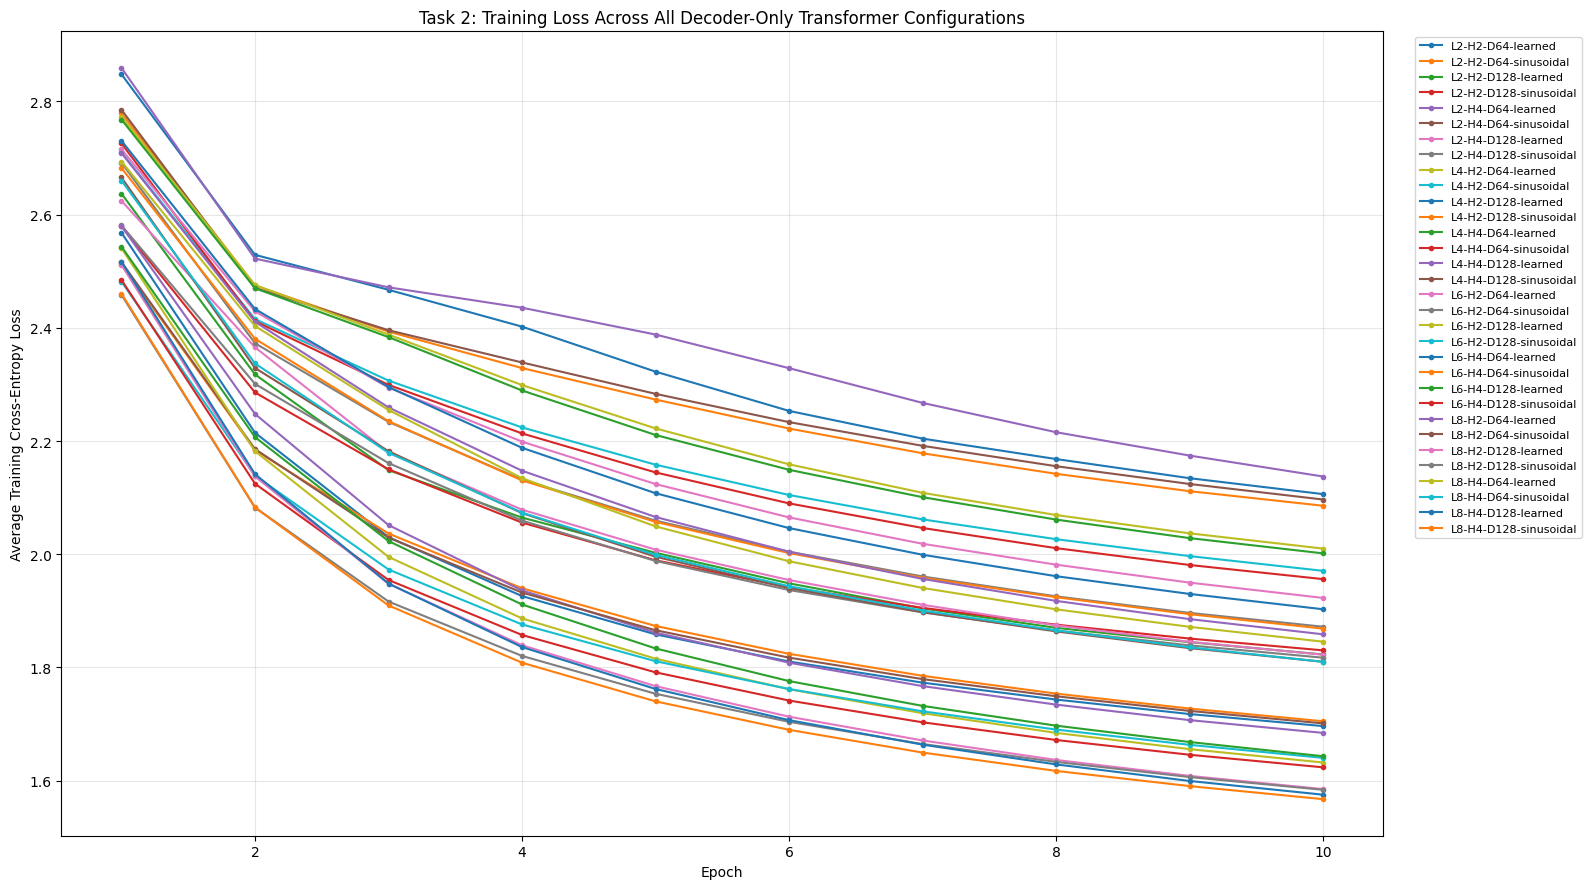

In [27]:
plt.figure(figsize=(16,9))
for result in experiment_results:
    h, c = result["history"], result["config"]
    label = f'L{c["layers"]}-H{c["heads"]}-D{c["d_model"]}-{c["positional"]}'
    plt.plot([r["epoch"] for r in h], [r["train_loss"] for r in h],
             marker="o", markersize=3, label=label)
plt.xlabel("Epoch")
plt.ylabel("Average Training Cross-Entropy Loss")
plt.title("Task 2: Training Loss Across All Decoder-Only Transformer Configurations")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 11. Epoch-wise logs and validation CE/PPL summary
The table explicitly includes architecture, number of completed epochs, best epoch, validation cross-entropy, validation perplexity, and runtime.

In [21]:
epoch_rows, summary_rows = [], []
for result in experiment_results:
    c, key = result["config"], result["model_key"]
    for row in result["history"]:
        epoch_rows.append({
            "Model": key, "Layers": c["layers"], "Heads": c["heads"],
            "d_model": c["d_model"], "Positional": c["positional"], **row
        })
    best = min(result["history"], key=lambda r: r["val_cross_entropy"])
    summary_rows.append({
        "Model": key, "Layers": c["layers"], "Heads": c["heads"],
        "d_model": c["d_model"], "Positional": c["positional"],
        "Epochs Completed": result["epochs_completed"],
        "Best Epoch": result["best_epoch"],
        "Best Validation CE": best["val_cross_entropy"],
        "Best Validation PPL": best["val_perplexity"],
        "Final Training Loss": result["history"][-1]["train_loss"],
        "Training Time (sec)": result["training_time_sec"]
    })

epoch_log_df = pd.DataFrame(epoch_rows)
validation_results_df = pd.DataFrame(summary_rows).sort_values(
    "Best Validation CE", ascending=True
).reset_index(drop=True)

print("EPOCH-WISE LOG (first 40 rows):")
display(epoch_log_df.head(40))
print("\nVALIDATION SUMMARY — ALL CONFIGURATIONS:")
display(validation_results_df)

EPOCH-WISE LOG (first 40 rows):


,Model,Layers,Heads,d_model,Positional,epoch,train_loss,train_perplexity,val_cross_entropy,val_perplexity,loss_difference,epoch_time_sec
0,L2_H2_D64_learned,2,2,64,learned,1,2.847987,17.253019,2.542413,12.710309,NaN,5.252221
1,L2_H2_D64_learned,2,2,64,learned,2,2.528970,12.540587,2.464738,11.760404,0.319017,4.928024
2,L2_H2_D64_learned,2,2,64,learned,3,2.467218,11.789602,2.399193,11.014282,0.061752,5.255954
3,L2_H2_D64_learned,2,2,64,learned,4,2.402104,11.046396,2.300347,9.977643,0.065114,5.354772
4,L2_H2_D64_learned,2,2,64,learned,5,2.322605,10.202220,2.198920,9.015268,0.079499,4.807538
5,L2_H2_D64_learned,2,2,64,learned,6,2.253241,9.518531,2.134989,8.456950,0.069365,5.171260
6,L2_H2_D64_learned,2,2,64,learned,7,2.204311,9.064008,2.087185,8.062188,0.048929,4.733309
7,L2_H2_D64_learned,2,2,64,learned,8,2.168195,8.742494,2.049774,7.766143,0.036116,4.675729
8,L2_H2_D64_learned,2,2,64,learned,9,2.134359,8.451623,2.016198,7.509718,0.033837,5.197219
9,L2_H2_D64_learned,2,2,64,learned,10,2.106227,8.217179,1.987742,7.299037,0.028132,4.631443



VALIDATION SUMMARY — ALL CONFIGURATIONS:


,Model,Layers,Heads,d_model,Positional,Epochs Completed,Best Epoch,Best Validation CE,Best Validation PPL,Final Training Loss,Training Time (sec)
0,L8_H4_D128_sinusoidal,8,4,128,sinusoidal,10,10,1.500714,4.484890,1.567263,347.181558
1,L8_H4_D128_learned,8,4,128,learned,10,10,1.512069,4.536108,1.575169,346.508759
2,L8_H2_D128_sinusoidal,8,2,128,sinusoidal,10,10,1.512461,4.537886,1.583819,302.008289
3,L8_H2_D128_learned,8,2,128,learned,10,10,1.513607,4.543086,1.585030,302.642727
4,L6_H4_D128_sinusoidal,6,4,128,sinusoidal,10,10,1.544205,4.684247,1.623514,259.783386
5,L6_H2_D128_learned,6,2,128,learned,10,10,1.551951,4.720672,1.632015,226.834889
6,L6_H2_D128_sinusoidal,6,2,128,sinusoidal,10,10,1.553853,4.729658,1.640174,227.951880
7,L6_H4_D128_learned,6,4,128,learned,10,10,1.564723,4.781349,1.643113,259.988434
8,L4_H4_D128_learned,4,4,128,learned,10,10,1.594190,4.924338,1.684361,175.416386
9,L4_H2_D128_learned,4,2,128,learned,10,10,1.598447,4.945348,1.696350,152.140427


## 12. Select the best model and report its validation metrics

The best model is selected using the lowest validation cross-entropy. The assignment asks for validation CE and PPL, not classification accuracy for this language-modelling task.

In [22]:
best_result = min(experiment_results, key=lambda r: r["best_val_loss"])
best_model_key = best_result["model_key"]
best_model = trained_models[best_model_key]
best_val_ppl = math.exp(min(best_result["best_val_loss"],20))

print("BEST MODEL — selected using validation cross-entropy")
print("Model key:", best_model_key)
print("Architecture:", best_result["config"])
print("Trainable parameters:", f"{count_parameters(best_model):,}")
print("Best epoch:", best_result["best_epoch"])
print("Epochs completed:", best_result["epochs_completed"])
print("Best validation CE:", f'{best_result["best_val_loss"]:.6f}')
print("Best validation PPL:", f"{best_val_ppl:.4f}")
print("Total training time (sec):", f'{best_result["training_time_sec"]:.1f}')

BEST MODEL — selected using validation cross-entropy
Model key: L8_H4_D128_sinusoidal
Architecture: {'layers': 8, 'heads': 4, 'd_model': 128, 'positional': 'sinusoidal'}
Trainable parameters: 1,606,221
Best epoch: 10
Epochs completed: 10
Best validation CE: 1.500714
Best validation PPL: 4.4849
Total training time (sec): 347.2


## 13. Text generation: greedy decoding and temperature sampling

- **Greedy decoding:** choose the character with the highest next-character probability.
- **Temperature sampling:** divide logits by temperature `τ` before softmax. Lower `τ` (0.5) makes sampling more conservative; higher `τ` (1.2) makes it more varied/random.

The model uses the most recent `BLOCK_SIZE` characters as context when generating each next character.

In [23]:
def generate_text(model, prompt, max_new_tokens=250, temperature=None):
    model.eval()
    # If a prompt contains characters not in the vocabulary, remove those characters.
    prompt_ids = [vocab[ch] for ch in prompt if ch in vocab]
    if len(prompt_ids) == 0:
        prompt_ids = [0]  # fallback to the first known character

    generated = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = generated[:, -BLOCK_SIZE:]
            logits = model(context)
            next_logits = logits[:, -1, :]

            if temperature is None:
                next_id = torch.argmax(next_logits, dim=-1, keepdim=True)
            else:
                if temperature <= 0:
                    raise ValueError("Temperature must be positive.")
                scaled_logits = next_logits / temperature
                probabilities = torch.softmax(scaled_logits, dim=-1)
                next_id = torch.multinomial(probabilities, num_samples=1)

            generated = torch.cat([generated, next_id], dim=1)

    return decode(generated[0].tolist())


# Five varied prompt/temperature examples, plus greedy examples.
generation_requests = [
    {"prompt": "ROMEO:", "mode": "greedy", "temperature": None},
    {"prompt": "To be, or not to be", "mode": "temperature sampling", "temperature": 0.5},
    {"prompt": "KING:", "mode": "temperature sampling", "temperature": 0.8},
    {"prompt": "What is the cause", "mode": "temperature sampling", "temperature": 1.2},
    {"prompt": "JULIET:", "mode": "temperature sampling", "temperature": 0.8},
    {"prompt": "HAMLET:", "mode": "greedy", "temperature": None},
    {"prompt": "I know not", "mode": "temperature sampling", "temperature": 0.5},
]

generated_examples = []
for i, request in enumerate(generation_requests, start=1):
    generated = generate_text(
        best_model,
        request["prompt"],
        max_new_tokens=250,
        temperature=request["temperature"]
    )
    generated_examples.append({
        "Sample": i,
        "Prompt": request["prompt"],
        "Decoding": request["mode"],
        "Temperature": "Greedy" if request["temperature"] is None else request["temperature"],
        "Generated Text": generated
    })
    print("\n" + "="*85)
    print(f'SAMPLE {i} | Prompt: {request["prompt"]!r} | '
          f'Mode: {request["mode"]} | Temperature: {request["temperature"]}')
    print("-"*85)
    print(generated)

generation_df = pd.DataFrame(generated_examples)
print("\nGeneration summary table:")
display(generation_df[["Sample","Prompt","Decoding","Temperature"]])


SAMPLE 1 | Prompt: 'ROMEO:' | Mode: greedy | Temperature: None
-------------------------------------------------------------------------------------
ROMEO: and the world of the world of the world,
And the stand of the country of the court,
And the strange of the court of the court,
And the strange of the court of the court,
And the strange of the court of the court,
And the strange of the court of the 

SAMPLE 2 | Prompt: 'To be, or not to be' | Mode: temperature sampling | Temperature: 0.5
-------------------------------------------------------------------------------------
To be, or not to be for the pardon ender
And the first of such and so of with the grace.
You have a thought for my lord, and sound to my son,
My lord lord, she will not to faith on his confess.
But me the common of my lord, the world most be
The part entreat of the con

SAMPLE 3 | Prompt: 'KING:' | Mode: temperature sampling | Temperature: 0.8
-----------------------------------------------------------------------

,Sample,Prompt,Decoding,Temperature
0,1,ROMEO:,greedy,Greedy
1,2,"To be, or not to be",temperature sampling,0.5
2,3,KING:,temperature sampling,0.8
3,4,What is the cause,temperature sampling,1.2
4,5,JULIET:,temperature sampling,0.8
5,6,HAMLET:,greedy,Greedy
6,7,I know not,temperature sampling,0.5


## 14. Causal triangular attention heatmaps (required)

We visualize attention weights from the final decoder layer. Each head's matrix must be lower triangular: a query at position `i` must assign zero attention to future key positions `j > i`. We show a short prefix to keep the heatmaps readable.

Attention architecture: {'layers': 8, 'heads': 4, 'd_model': 128, 'positional': 'sinusoidal'}
Visualized layer: final decoder layer
Tokens: ['T', 'o', ' ', 'b', 'e', ',', ' ', 'o', 'r', ' ', 'n', 'o', 't', ' ', 't', 'o', ' ', 'b', 'e']


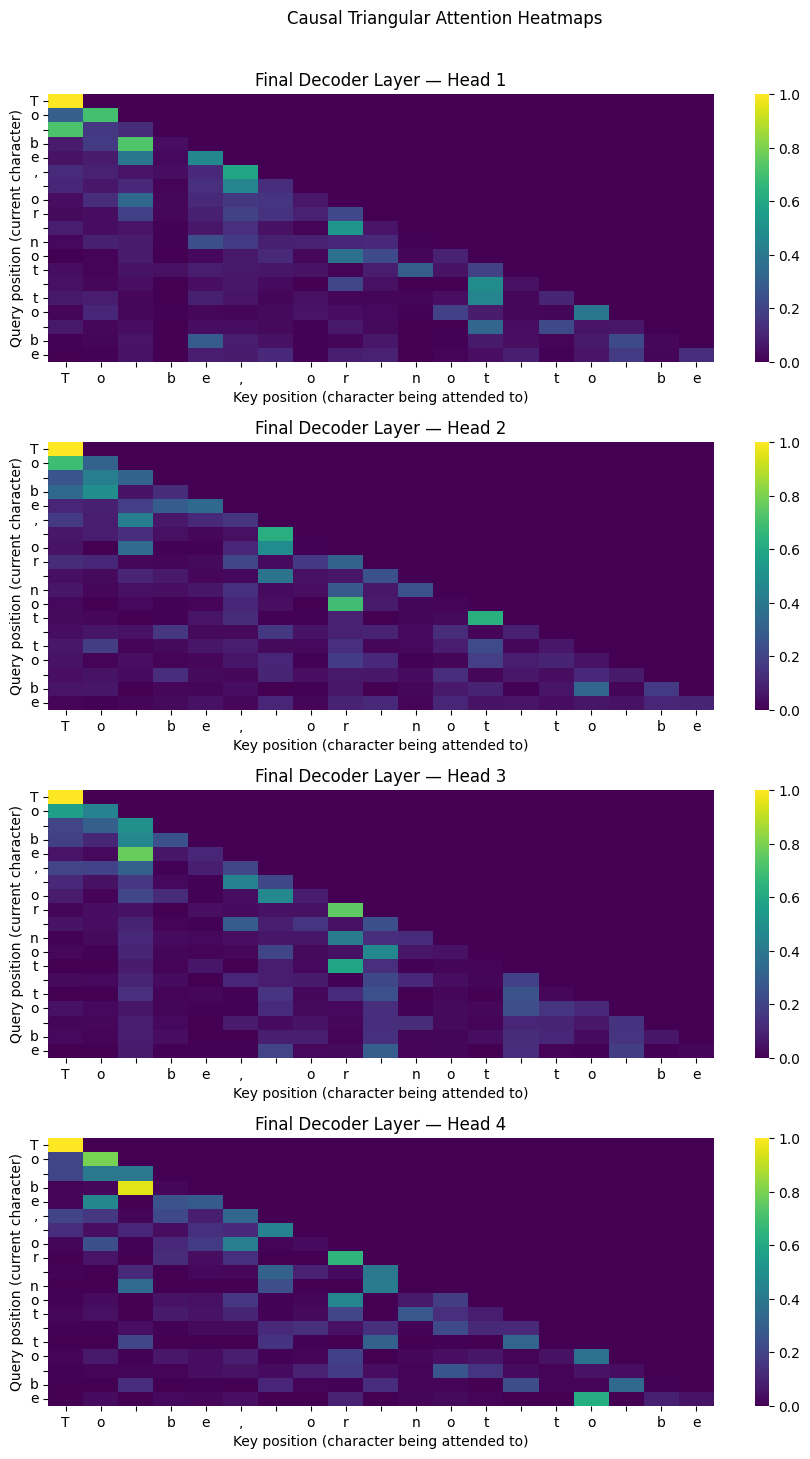

Maximum attention assigned to future positions: 0.0
Expected value: approximately 0


In [24]:
ATTENTION_PREFIX = "To be, or not to be"
attention_ids = [vocab[ch] for ch in ATTENTION_PREFIX if ch in vocab]
attention_input = torch.tensor([attention_ids], dtype=torch.long, device=DEVICE)

best_model.eval()
with torch.no_grad():
    attention_logits, all_attention = best_model(attention_input, return_attention=True)

# Last layer attention shape: (batch, heads, query_positions, key_positions).
last_attention = all_attention[-1][0].detach().cpu().numpy()
num_heads = last_attention.shape[0]
tokens = list(ATTENTION_PREFIX[:len(attention_ids)])
display_len = min(len(tokens), 30)

print("Attention architecture:", best_result["config"])
print("Visualized layer: final decoder layer")
print("Tokens:", tokens[:display_len])

fig, axes = plt.subplots(num_heads, 1, figsize=(9, 3.6*num_heads))
if num_heads == 1:
    axes = [axes]
for h, ax in enumerate(axes):
    matrix = last_attention[h, :display_len, :display_len]
    sns.heatmap(
        matrix, ax=ax, cmap="viridis", vmin=0,
        xticklabels=tokens[:display_len],
        yticklabels=tokens[:display_len]
    )
    ax.set_title(f"Final Decoder Layer — Head {h+1}")
    ax.set_xlabel("Key position (character being attended to)")
    ax.set_ylabel("Query position (current character)")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Causal Triangular Attention Heatmaps", y=1.01)
plt.tight_layout()
plt.show()

# Numerical check: attention to future positions should be approximately zero.
future_mask = np.triu(np.ones((display_len,display_len),dtype=bool),k=1)
max_future_attention = max(
    float(np.max(last_attention[h,:display_len,:display_len][future_mask]))
    for h in range(num_heads)
)
print("Maximum attention assigned to future positions:", max_future_attention)
print("Expected value: approximately 0")

## 15. Empirical discussion: heads, depth, and runtime

Use grouped validation cross-entropy/perplexity and runtime to compare the effect of attention-head count and Transformer depth. Lower validation CE/PPL is better. These are empirical averages across configurations; mention that model dimension and positional encoding also vary.

Average validation metrics grouped by attention heads:


,Heads,Best Validation CE,Best Validation PPL,Training Time (sec)
0,2,1.710770,5.591568,149.722108
1,4,1.709897,5.590018,176.788217



Average validation metrics grouped by depth:


,Layers,Best Validation CE,Best Validation PPL,Training Time (sec)
0,2,1.835976,6.327315,70.668790
1,4,1.726222,5.665386,131.456157
2,6,1.663552,5.310712,193.874287
3,8,1.615585,5.059760,257.021418


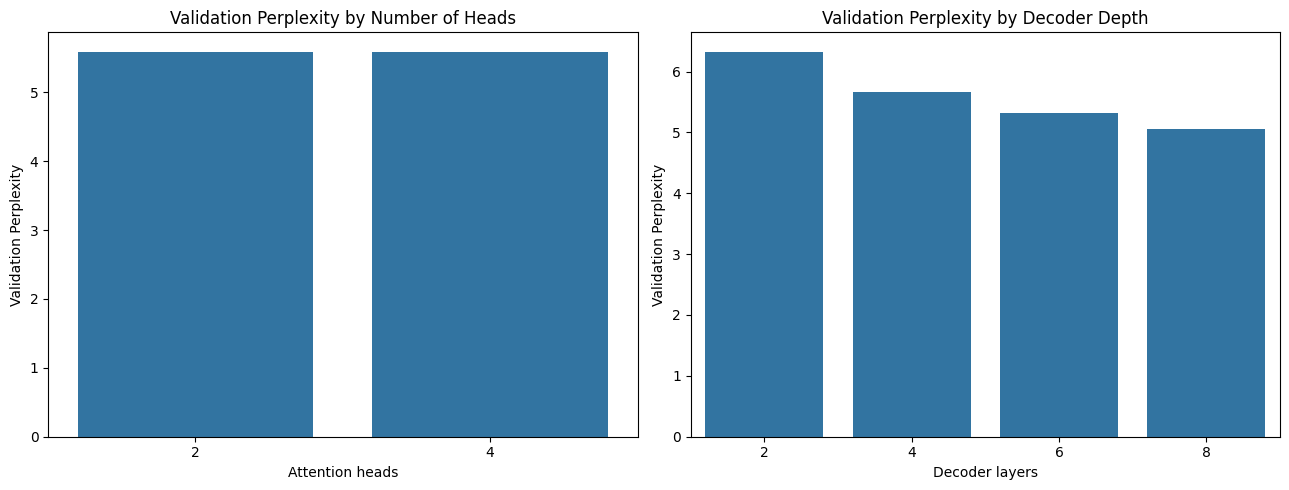

Average epoch time by depth:


,Layers,Average seconds per epoch
0,2,7.063318
1,4,13.139966
2,6,19.378852
3,8,25.691947


In [25]:
print("Average validation metrics grouped by attention heads:")
display(validation_results_df.groupby("Heads")[
    ["Best Validation CE","Best Validation PPL","Training Time (sec)"]
].mean().reset_index())

print("\nAverage validation metrics grouped by depth:")
display(validation_results_df.groupby("Layers")[
    ["Best Validation CE","Best Validation PPL","Training Time (sec)"]
].mean().reset_index())

fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.barplot(data=validation_results_df,x="Heads",y="Best Validation PPL",
            ax=axes[0],errorbar=None)
axes[0].set_title("Validation Perplexity by Number of Heads")
axes[0].set_xlabel("Attention heads")
axes[0].set_ylabel("Validation Perplexity")

sns.barplot(data=validation_results_df,x="Layers",y="Best Validation PPL",
            ax=axes[1],errorbar=None)
axes[1].set_title("Validation Perplexity by Decoder Depth")
axes[1].set_xlabel("Decoder layers")
axes[1].set_ylabel("Validation Perplexity")
plt.tight_layout()
plt.show()

print("Average epoch time by depth:")
display(epoch_log_df.groupby("Layers")["epoch_time_sec"].mean().reset_index(
    name="Average seconds per epoch"))

## 16. Save result tables, generated samples, and best model checkpoint

In [26]:
OUTPUT_DIR = "/content/task2_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

epoch_log_df.to_csv(os.path.join(OUTPUT_DIR,"task2_epoch_wise_log.csv"),index=False)
validation_results_df.to_csv(os.path.join(OUTPUT_DIR,"task2_validation_ce_ppl_all_configurations.csv"),index=False)
generation_df.to_csv(os.path.join(OUTPUT_DIR,"task2_generated_text_samples.csv"),index=False)

torch.save({
    "model_key": best_model_key,
    "architecture": best_result["config"],
    "vocab": vocab,
    "state_dict": best_model.state_dict(),
    "block_size": BLOCK_SIZE,
    "vocab_size": VOCAB_SIZE
}, os.path.join(OUTPUT_DIR,"best_task2_shakespeare_gpt.pt"))

with open(os.path.join(OUTPUT_DIR,"task2_generated_samples.txt"),"w",encoding="utf-8") as f:
    for item in generated_examples:
        f.write(f'PROMPT: {item["Prompt"]}\n')
        f.write(f'DECODING: {item["Decoding"]} | TEMPERATURE: {item["Temperature"]}\n')
        f.write(item["Generated Text"] + "\n")
        f.write("="*80 + "\n")

print("Saved files:")
for name in sorted(os.listdir(OUTPUT_DIR)):
    print("-",name)

Saved files:
- best_task2_shakespeare_gpt.pt
- task2_epoch_wise_log.csv
- task2_generated_samples.txt
- task2_generated_text_samples.csv
- task2_validation_ce_ppl_all_configurations.csv


## 17. Report discussion checklist

Use the actual output values from your run.

1. **Best configuration:** state decoder layers, heads, `d_model`, positional encoding, parameter count, best epoch, epochs completed, validation CE, validation PPL, and runtime.
2. **Cross-entropy and perplexity:** validation perplexity is the exponential of validation cross-entropy. Lower values indicate better next-character prediction on the validation stream.
3. **Attention heads:** compare the mean validation CE/PPL for 2 versus 4 heads. Multiple heads can represent different dependencies, but extra heads do not automatically improve performance.
4. **Depth:** compare 2 versus 4 decoder blocks. Greater depth may learn more complex sequential patterns, but usually increases computation.
5. **Temperature:** lower temperature tends to produce more predictable text; higher temperature tends to produce more varied but potentially less coherent text.
6. **Greedy versus sampling:** greedy always selects the most probable next character; sampling can produce alternative continuations.
7. **Causal mask:** the heatmaps should show no attention to future positions. This is what preserves autoregressive generation.

**Limitations:** this is a character-level model trained from scratch on the supplied Shakespeare corpus, not a pretrained GPT model. The optional bonus depth study (`L=6,8`) is not included in the 16 required baseline configurations.

**Submission reminder:** save this notebook as `code.ipynb`, keep outputs visible, and place the generated plots, tables, text samples, and discussion in `report.pdf`.